# Self-Supervised, Drift-Aware IoT Intrusion Detection — Quickstart

This notebook walks through the full pipeline on **synthetic CIC-IoT2023-like data** so it runs in a few minutes on a laptop. Switch to `configs/default.yaml` once you have downloaded the real dataset.

**Protocol:** models see *benign traffic only*. Attack families `Mirai, Web, BruteForce, Spoofing` are held out completely → the test measures detection of **unknown (zero-day) attacks**.

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT / 'src'))
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import Image, display
from iotids.config import load_config
from iotids.data import load_dataset, make_splits
from iotids.pipeline import run_batch, run_stream
from iotids.synthetic import write_csvs
pd.set_option('display.precision', 4)

## 1. Data

In [2]:
if not Path('data/synthetic').exists():
    write_csvs('data/synthetic')
cfg = load_config('configs/synthetic.yaml')
df = load_dataset(cfg)
print(df.shape)
df['family'].value_counts().plot.barh(title='Rows per family', figsize=(6, 3));

(84000, 27)


In [3]:
feats = ['Rate', 'Tot size', 'syn_flag_number', 'IAT']
fig, axes = plt.subplots(1, 4, figsize=(15, 3))
for ax, f in zip(axes, feats):
    for fam, g in df.groupby('family'):
        ax.hist(np.log1p(g[f].replace(np.inf, np.nan).dropna()), bins=60, histtype='step', density=True, label=fam)
    ax.set_title(f'log1p({f})')
axes[0].legend(fontsize=7); plt.tight_layout()

## 2. Zero-day split

In [4]:
sp = make_splits(df, cfg)
pd.DataFrame(sp.summary()).fillna(0).astype(int)

,train,val,test,known
Benign,36000,12000,12000,0
Web,0,0,4500,0
Mirai,0,0,3000,0
Spoofing,0,0,3000,0
BruteForce,0,0,1500,0
Recon,0,0,0,4500
DDoS,0,0,0,4500
DoS,0,0,0,3000


## 3. Train all detectors & evaluate on unknown attack families

In [5]:
run = run_batch(cfg)


      model                        eval  precision  recall     f1    fpr  threshold  roc_auc  pr_auc  tpr@fpr=1%  fpr@tpr=95%  fit_seconds  infer_us_per_flow
    iforest zero-day (unknown families)     0.9772  0.4146 0.5822 0.0097     0.5113   0.9300  0.9305      0.4233       0.3274       0.6096            17.0775
    iforest              known families     0.9802  0.4796 0.6441 0.0097     0.5113   0.9520  0.9519      0.4906       0.2180          NaN                NaN
      ocsvm zero-day (unknown families)     0.9835  0.5758 0.7263 0.0097     0.0045   0.9561  0.9608      0.5845       0.2828       0.3096             3.3469
      ocsvm              known families     0.9861  0.6858 0.8089 0.0097     0.0045   0.9684  0.9733      0.6965       0.1671          NaN                NaN
         ae zero-day (unknown families)     0.9894  0.7982 0.8836 0.0086     0.2783   0.9871  0.9876      0.8154       0.0731      27.0623             3.2683
         ae              known families     0.9903 

In [6]:
m = pd.read_csv(run / 'metrics.csv')
m[['model','eval','roc_auc','pr_auc','tpr@fpr=1%','precision','recall','f1','fpr']]

,model,eval,roc_auc,pr_auc,tpr@fpr=1%,precision,recall,f1,fpr
0,iforest,zero-day (unknown families),0.9300,0.9305,0.4233,0.9772,0.4146,0.5822,0.0097
1,iforest,known families,0.9520,0.9519,0.4906,0.9802,0.4796,0.6441,0.0097
2,ocsvm,zero-day (unknown families),0.9561,0.9608,0.5845,0.9835,0.5757,0.7263,0.0097
3,ocsvm,known families,0.9684,0.9733,0.6965,0.9861,0.6857,0.8089,0.0097
4,ae,zero-day (unknown families),0.9871,0.9876,0.8154,0.9894,0.7983,0.8836,0.0086
5,ae,known families,0.9928,0.9931,0.8902,0.9903,0.8757,0.9295,0.0086
6,vae,zero-day (unknown families),0.9885,0.9891,0.8329,0.9890,0.8163,0.8944,0.0091
7,vae,known families,0.9911,0.9917,0.8756,0.9896,0.8622,0.9215,0.0091
8,contrastive,zero-day (unknown families),0.9791,0.9802,0.7343,0.9870,0.7279,0.8379,0.0096
9,contrastive,known families,0.9819,0.9819,0.7257,0.9869,0.7192,0.8321,0.0096


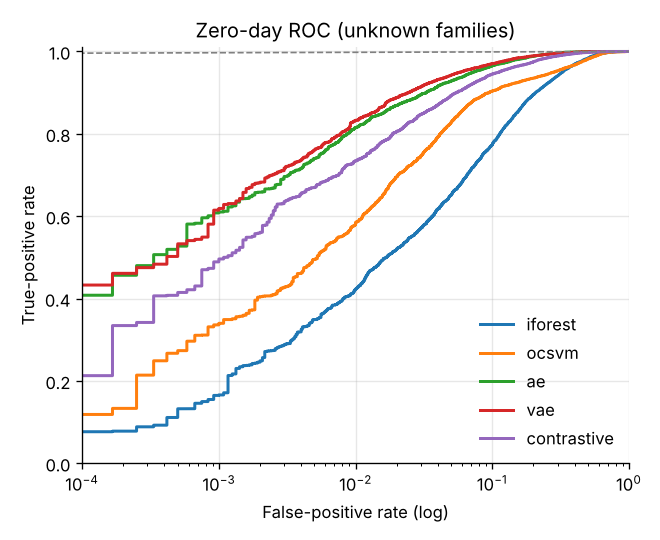

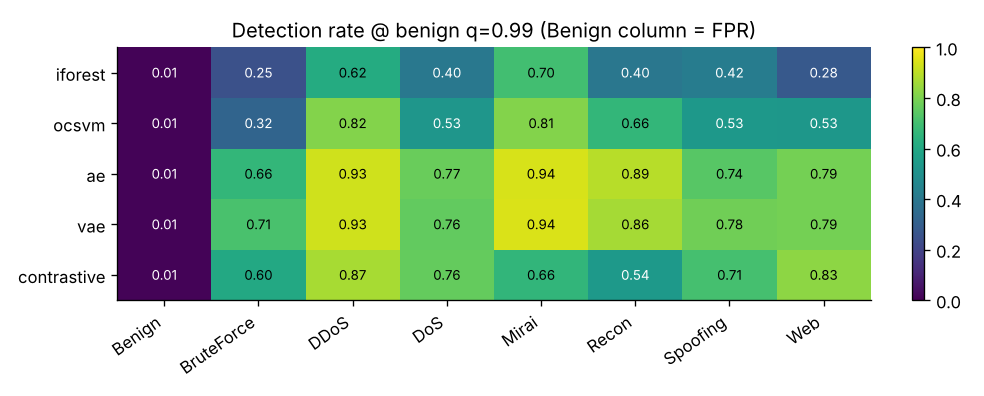

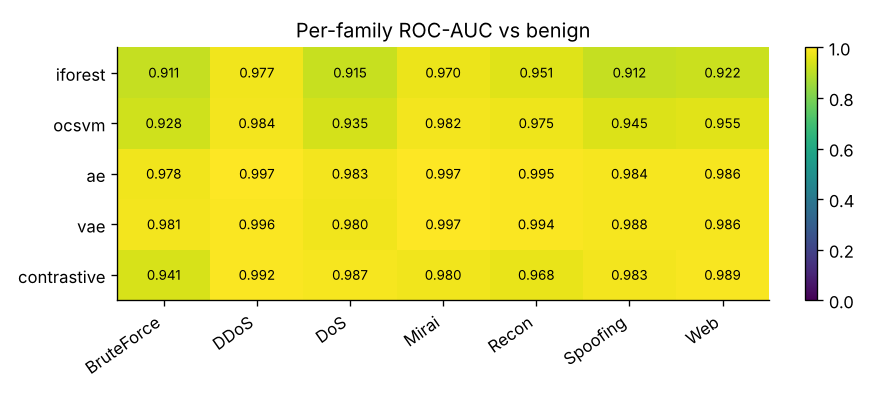

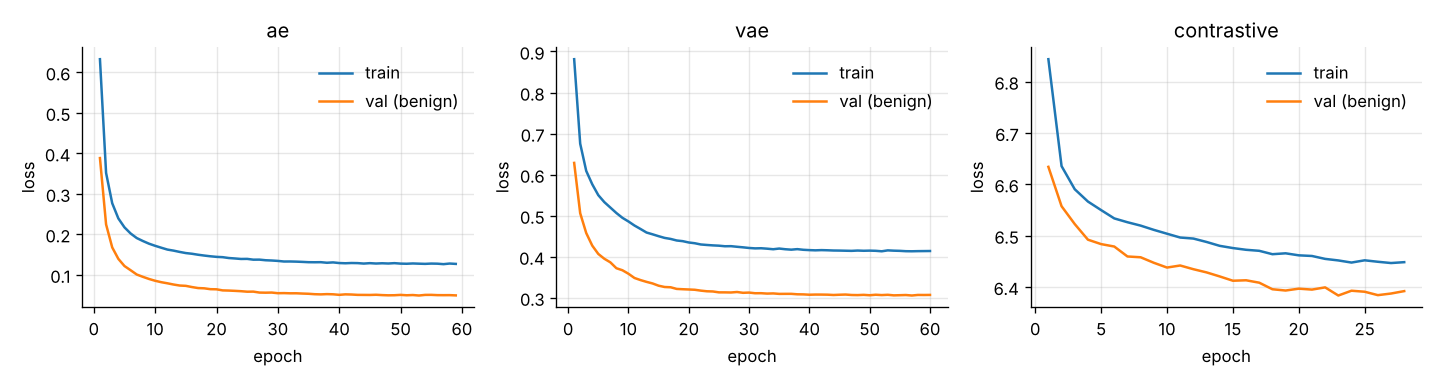

In [7]:
for f in ['roc_zero_day.png', 'per_family_detection.png', 'per_family_auc.png', 'training_curves.png']:
    display(Image(run / 'figures' / f))

## 4. Concept drift: static vs self-adapting detector

Benign traffic shifts at `ts = 0.6` (think: firmware update). The static model's false-positive rate explodes; the adaptive model detects the drift with ADWIN (label-free), fine-tunes on likely-benign recent traffic plus a replay buffer, and re-calibrates its threshold.


    mode     period    fpr  recall  windows
adaptive  pre-drift 0.0246  0.8817        9
adaptive post-drift 0.0078  0.6662       33
  static  pre-drift 0.0246  0.8817        9
  static post-drift 0.1683  0.9434       33
adaptations: 1
Artifacts -> runs/synthetic-stream-ae-20261109-232558


,mode,period,fpr,recall,windows
0,adaptive,pre-drift,0.0246,0.8817,9
1,adaptive,post-drift,0.0078,0.6662,33
2,static,pre-drift,0.0246,0.8817,9
3,static,post-drift,0.1683,0.9434,33


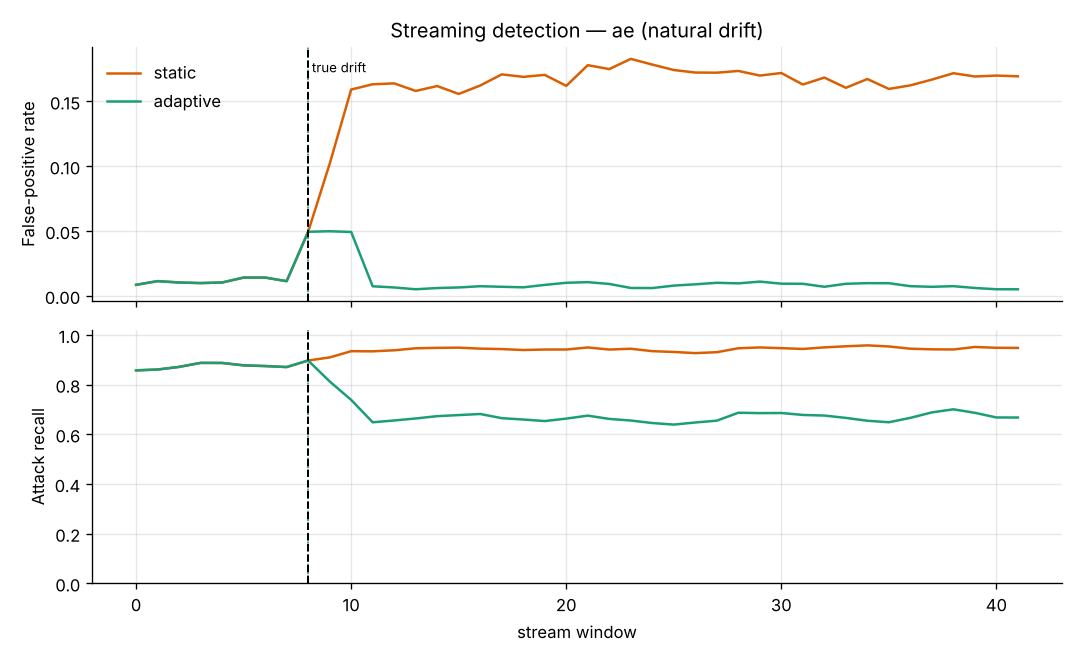

In [8]:
srun = run_stream(cfg, 'ae')
display(pd.read_csv(srun / 'stream_summary.csv'))
display(Image(srun / 'figures' / 'stream_static_vs_adaptive.png'))

## 5. Next steps
- Download CIC-IoT2023 (see `data/README.md`) and run `iotids all --config configs/default.yaml`
- Try other `unknown_families` choices (leave-one-family-out)
- `streamlit run app/streamlit_app.py` for the dashboard